In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
from sklearn.metrics import accuracy_score

In [2]:
heart = pd.read_csv("F:\MACHINE LEARNING\SOMETHING\Datasets\heart.csv")
heart.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
X,y=heart.drop('target',axis=1),heart.target
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.3,random_state=26,stratify=y)


In [4]:

depths = [None, 2,3,4,5,6,7]
min_split = [2,0.05,0.01,0.2,0.3]
min_leaf = [1,0.05,0.01,0.2,0.3]
scores=[]
for d in depths:
    for l in min_leaf:
        for s in min_split:
            dt=DecisionTreeClassifier(random_state=26,max_depth=d,min_samples_leaf=l,min_samples_split=s)
            dt.fit(X_train,y_train)
            pred=dt.predict(X_test)
            scores.append([d,l,s,accuracy_score(y_test,pred)])
score_df=pd.DataFrame(scores,columns=["depths",'min_split','min_leaf','accuracy' ])
score_df.sort_values(by="accuracy",ascending=False,ignore_index=True)

,depths,min_split,min_leaf,accuracy
0,NaN,1.00,0.01,0.780220
1,7.0,1.00,0.01,0.780220
2,6.0,1.00,0.01,0.780220
3,6.0,1.00,2.00,0.780220
4,5.0,1.00,0.01,0.769231
...,...,...,...,...
170,6.0,0.05,2.00,0.703297
171,6.0,0.05,0.01,0.703297
172,7.0,0.05,0.01,0.703297
173,7.0,0.05,2.00,0.703297


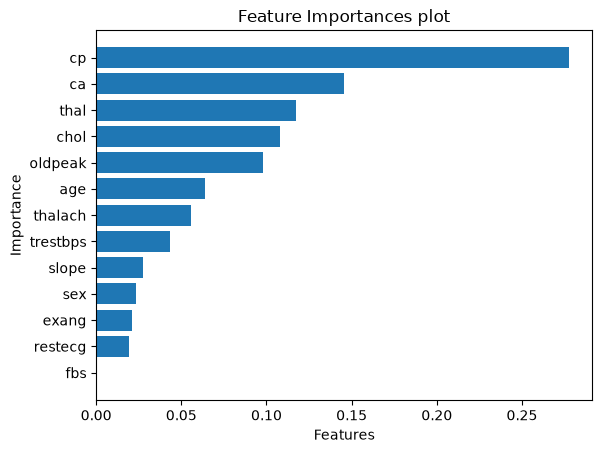

In [7]:
best_tree = DecisionTreeClassifier(random_state=26, max_depth = 7, min_samples_split= 2, min_samples_leaf= 1)
best_tree.fit(X, y)
df_imp = pd.DataFrame({'features': list(X.columns),
                       'importance': best_tree.feature_importances_})
df_imp.sort_values('importance', inplace = True)
plt.barh(df_imp['features'], df_imp['importance'])
plt.title("Feature Importances plot")
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()